In [3]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parents[1]))
from extract_features.lib import *

This notebook implements MVAR modeling per window (epoch) which is an instance in the bag (exam) during [MIL](https://torchmil.readthedocs.io/en/main/). Each window:
- is z-scored
- has AR coefficients computed
- has H computed (from AR)
- has NDTF & ffDTF computed and aggregated per freqiency bands (sum or average)
- has heatmap, "circle" form mne-connectivity and graph representation

In graph domain each window can be represented band-wise as:
- dense graphs (that can have traditional graph analysis metrics compueted)
- sparse graphs (choosing only the strongest connections in reference to all or band-local)

The graphs have positions set to the applied standard 1020 montage to see the effective connectivity more intuitively on the scalp-sensor space.

It seems that the spase graphs in global mode can be a good candidate for window graph representation for graph NNs implemented from [PyG](https://pytorch-geometric.readthedocs.io/en/latest/).

All functions with documentation are in the library (lib.py) and all constants are in configuration file (config.py).

The aim is to investigate if effective (causal) connectivity (explicitly not-normalised DTF (NDTF) and full-frequency normalised DTF (ffDTF)) can be represented as a graph. The study also checks if the representation can be sparsed to discard week connections, that instead of being real direct connections, act as noise.

In [4]:
fpr = load_eeg_memmap()
single_exam = fpr[48] #randomly pick a recording

In [5]:
#sanity check
#single_exam.shape

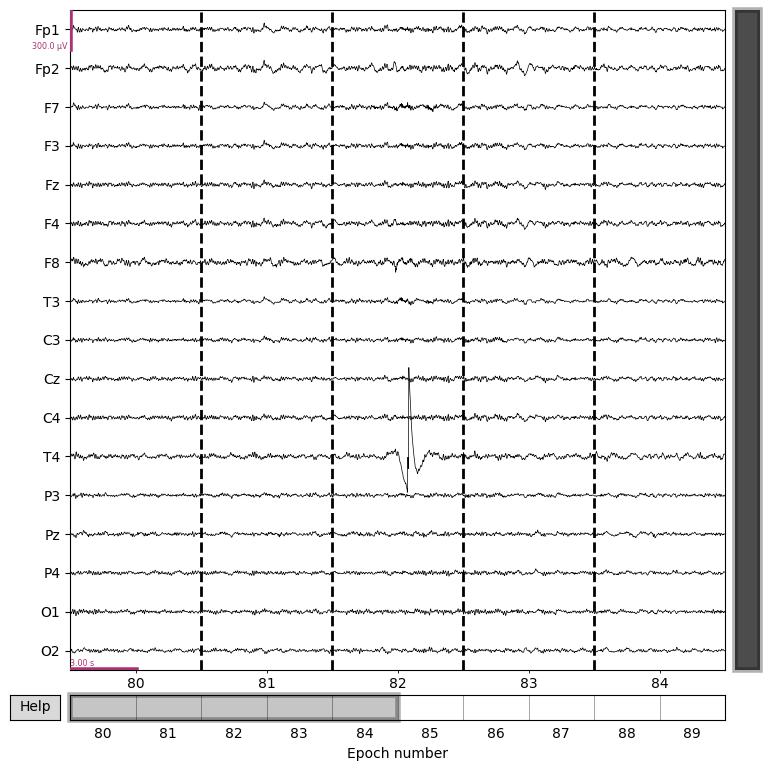

In [6]:
g = plot_epoch_eeg(single_exam, 
                   start_epoch = 80, 
                   end_epoch = 90, 
                   n_epochs_to_plot = 5, 
                   scalings = dict(eeg=150e-6))

In [7]:
one_window = single_exam[82, :, :]

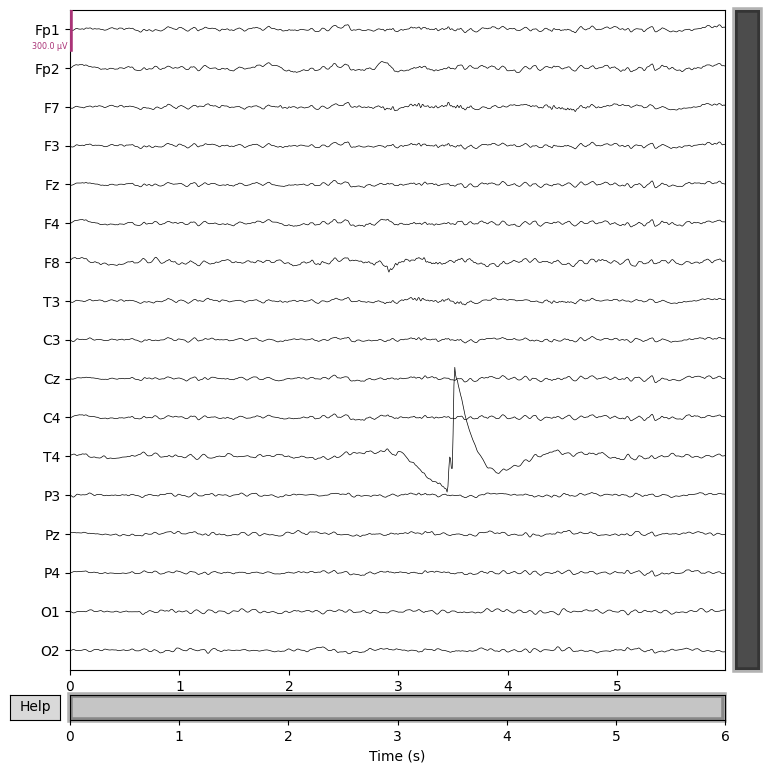

In [8]:
g = plot_one_window(one_window, scalings = dict(eeg=150e-6))

# prepare for modelling

In [9]:
one_window_zscored = zscore_per_channel(one_window)
one_window_zscored

array([[-0.7297962 , -0.82360774, -0.97739816, ...,  1.5255083 ,
         1.2363273 ,  0.8360778 ],
       [-0.0609549 ,  0.06929657,  0.3618778 , ...,  1.0901366 ,
         1.005478  ,  1.0113893 ],
       [-0.6503777 , -0.8834763 , -1.0547713 , ...,  1.2865978 ,
         0.8694638 ,  0.46288168],
       ...,
       [-0.3021204 , -0.09001406,  0.19821446, ..., -0.6567875 ,
        -0.4336849 , -0.05752534],
       [ 0.34637693, -0.1361809 , -0.63376874, ...,  1.4023273 ,
         1.2347983 ,  0.5669784 ],
       [-0.40359467, -0.07062432,  0.263138  , ..., -1.4182444 ,
        -1.2583722 , -0.9992437 ]], shape=(17, 768), dtype=float32)

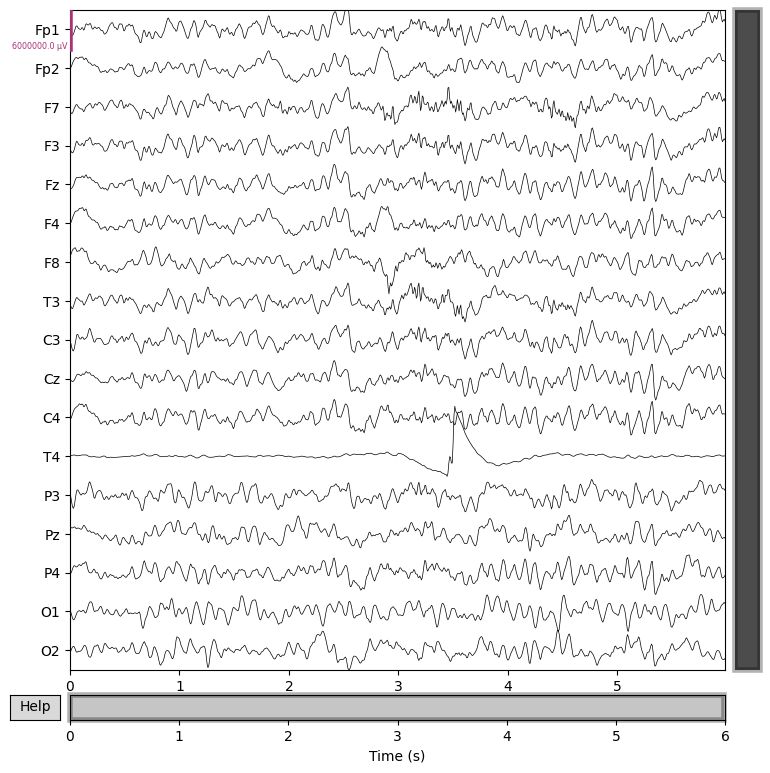

In [10]:
g = plot_one_window(one_window_zscored, scalings = dict(eeg=3))

For my application it is save to set common order to 9 (we are aiming at around 5 frequency peaks) (this is shown in another notebook by sampling the dataset to probe for PSDs and AIC criterion). Considering the set length of the epoch to 6 x 128 the unbiased version of the algorithm can be safely used (iwhat = 2).

## input: one epoch

### standard approach

In [11]:
AR, _ = AR_coeff(one_window_zscored)
mvar_H = mvar_H(AR)

### prepare band-averaged features of non-normalized DTF (magnitude) & frequency normalized DTF

In [12]:
NDTF = np.abs(mvar_H) ** 2 #not normalized
ffDTF = ffDTF(mvar_H)

## visualization for one directed information flow

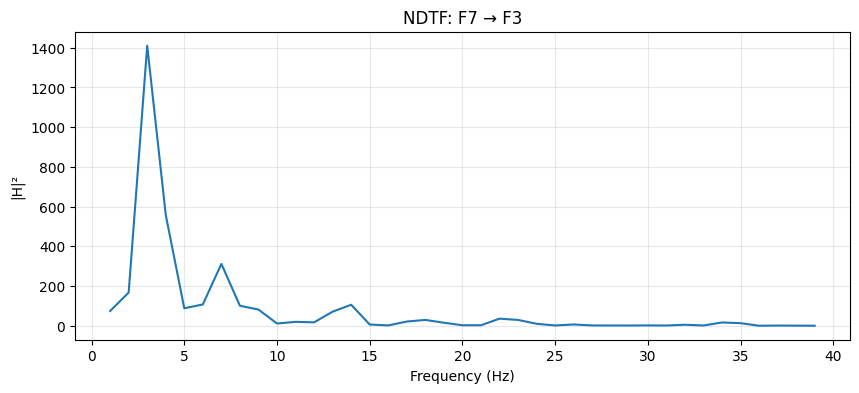

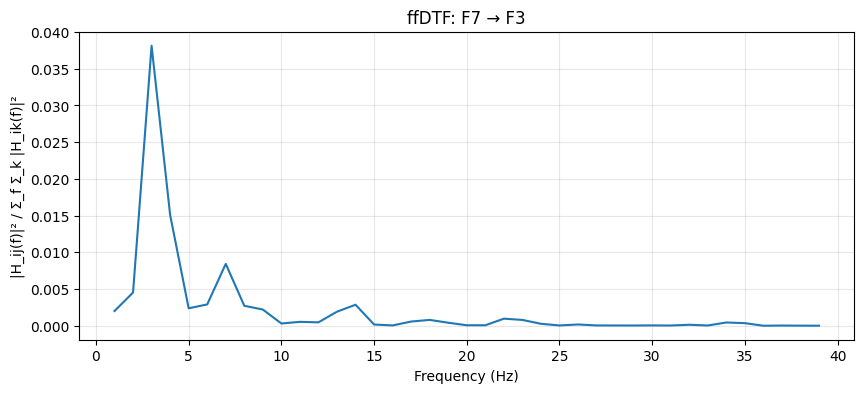

In [13]:
plot_one_flow(NDTF, 2, 3, ylabel = "|H|²", conn_name = 'NDTF')
plot_one_flow(ffDTF, 2, 3)

It looks as predicted -> very similar with other values on y axis.

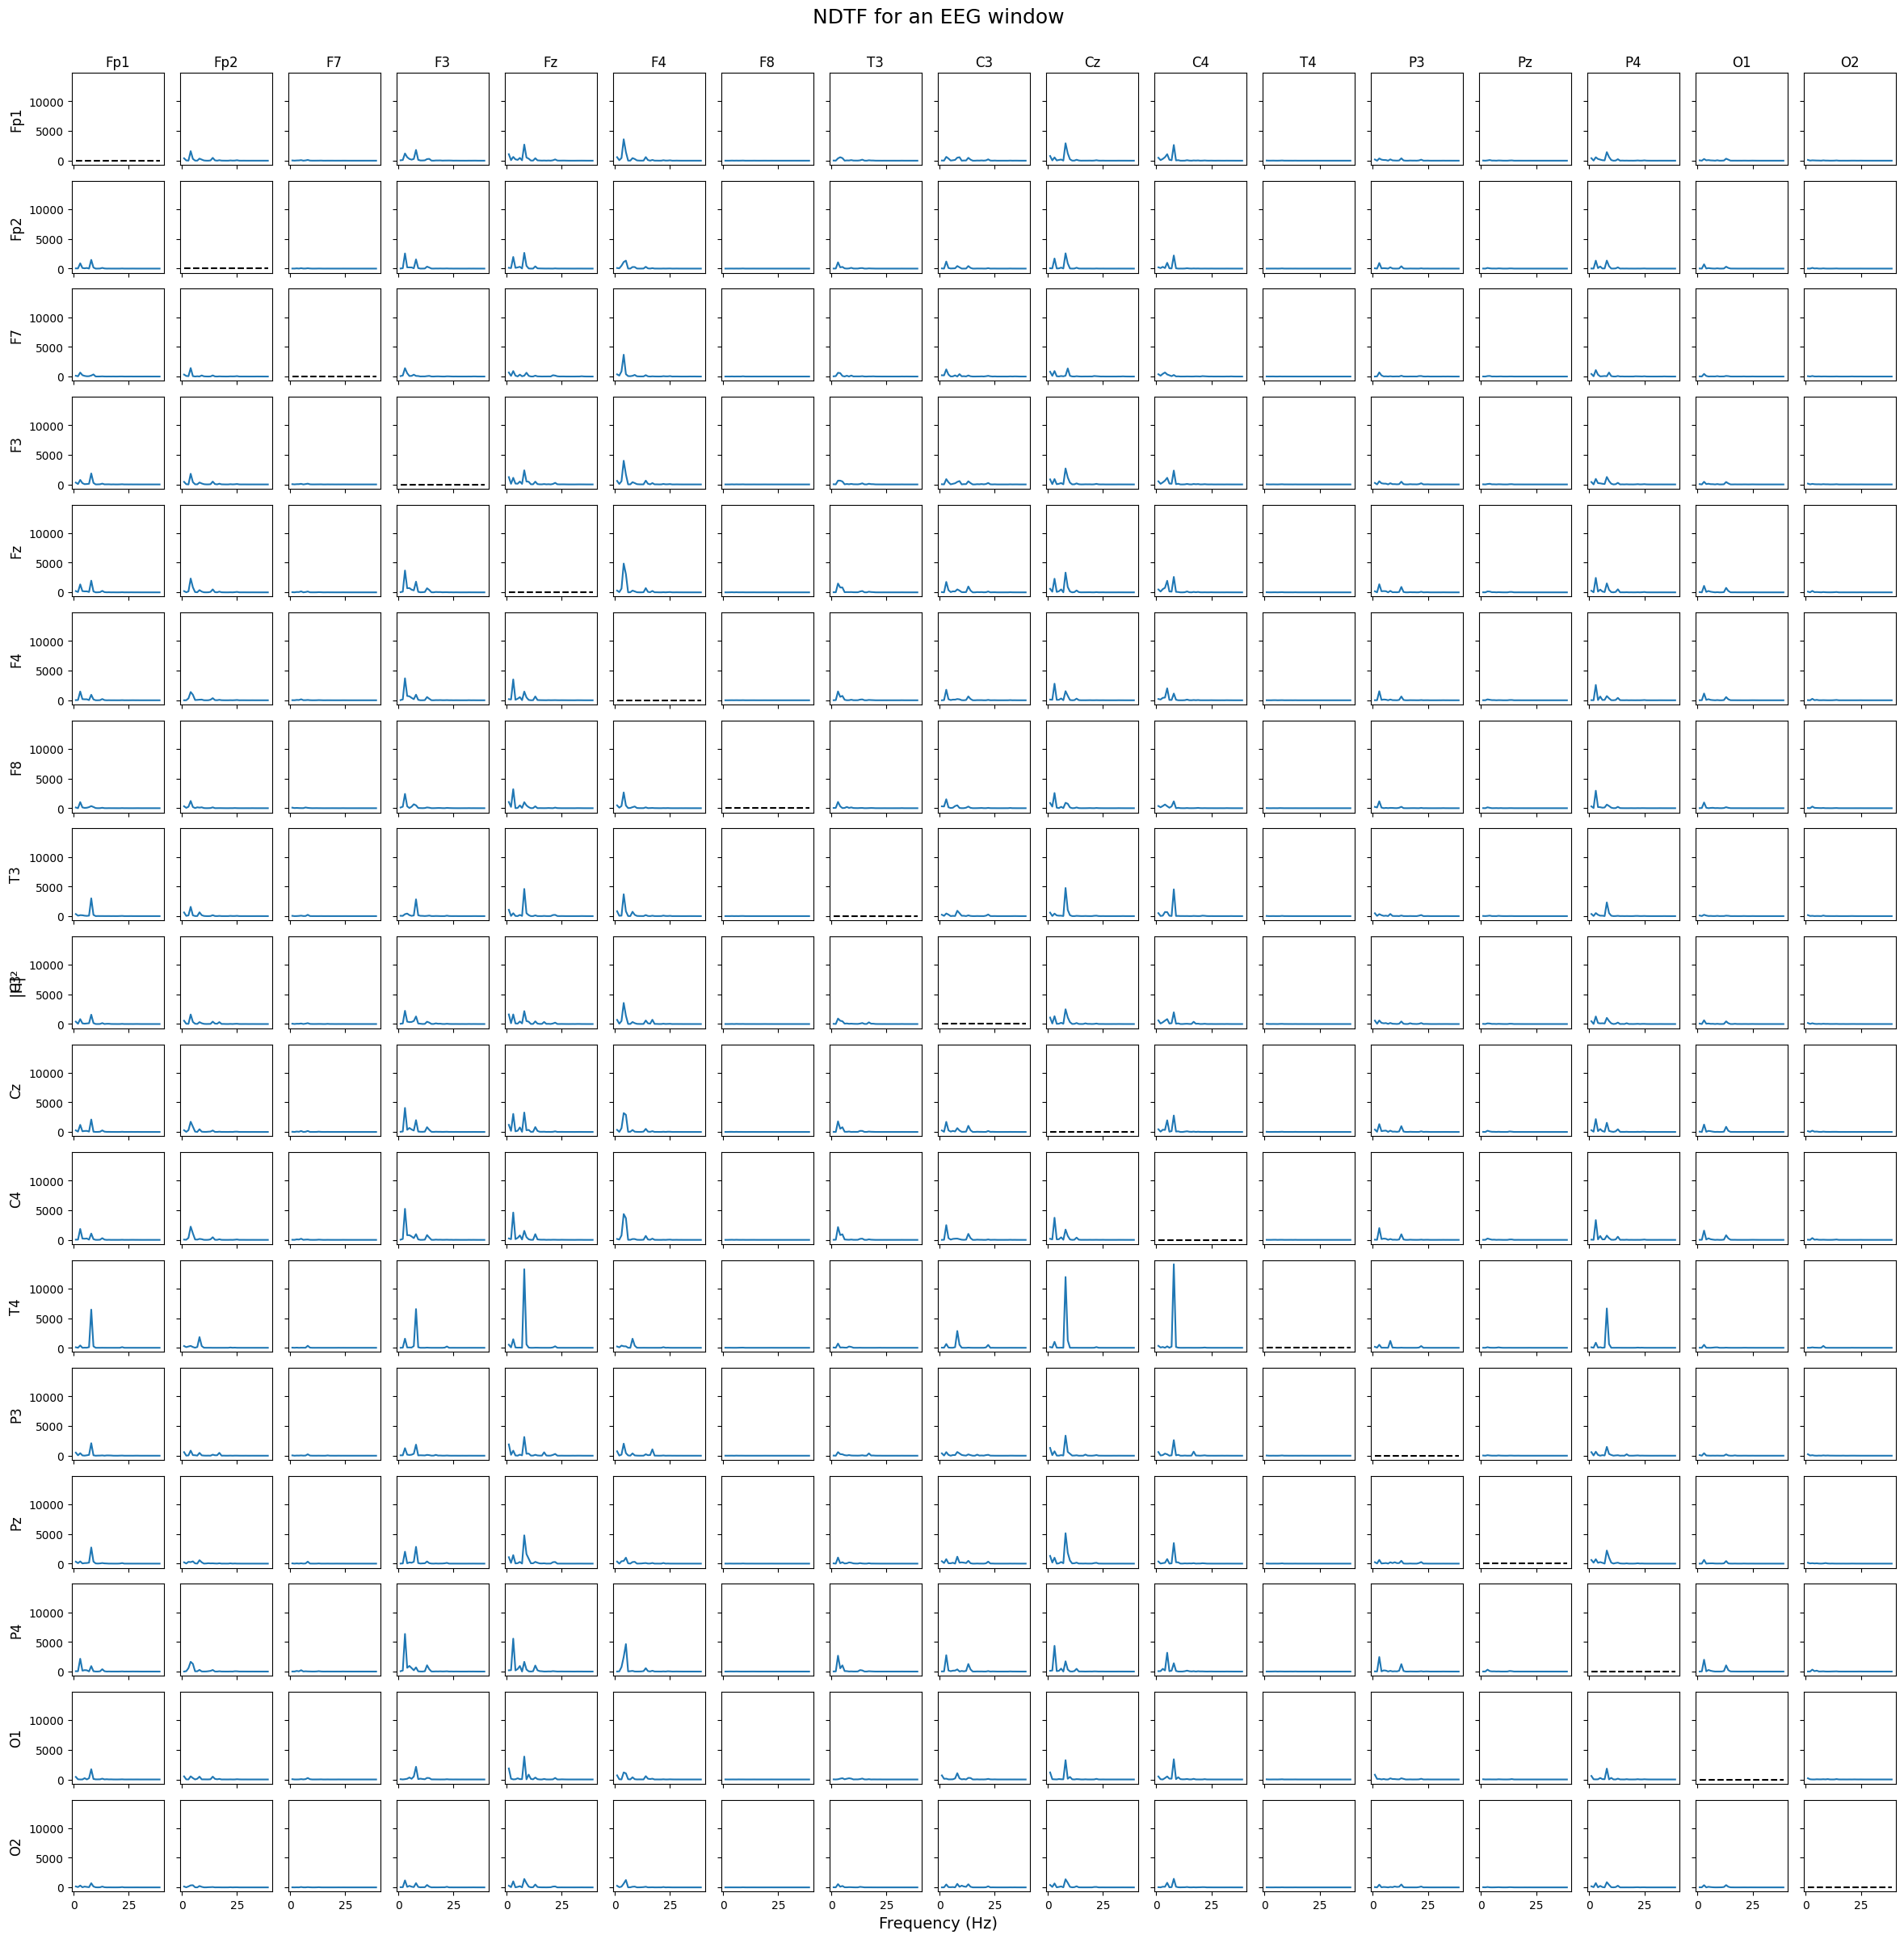

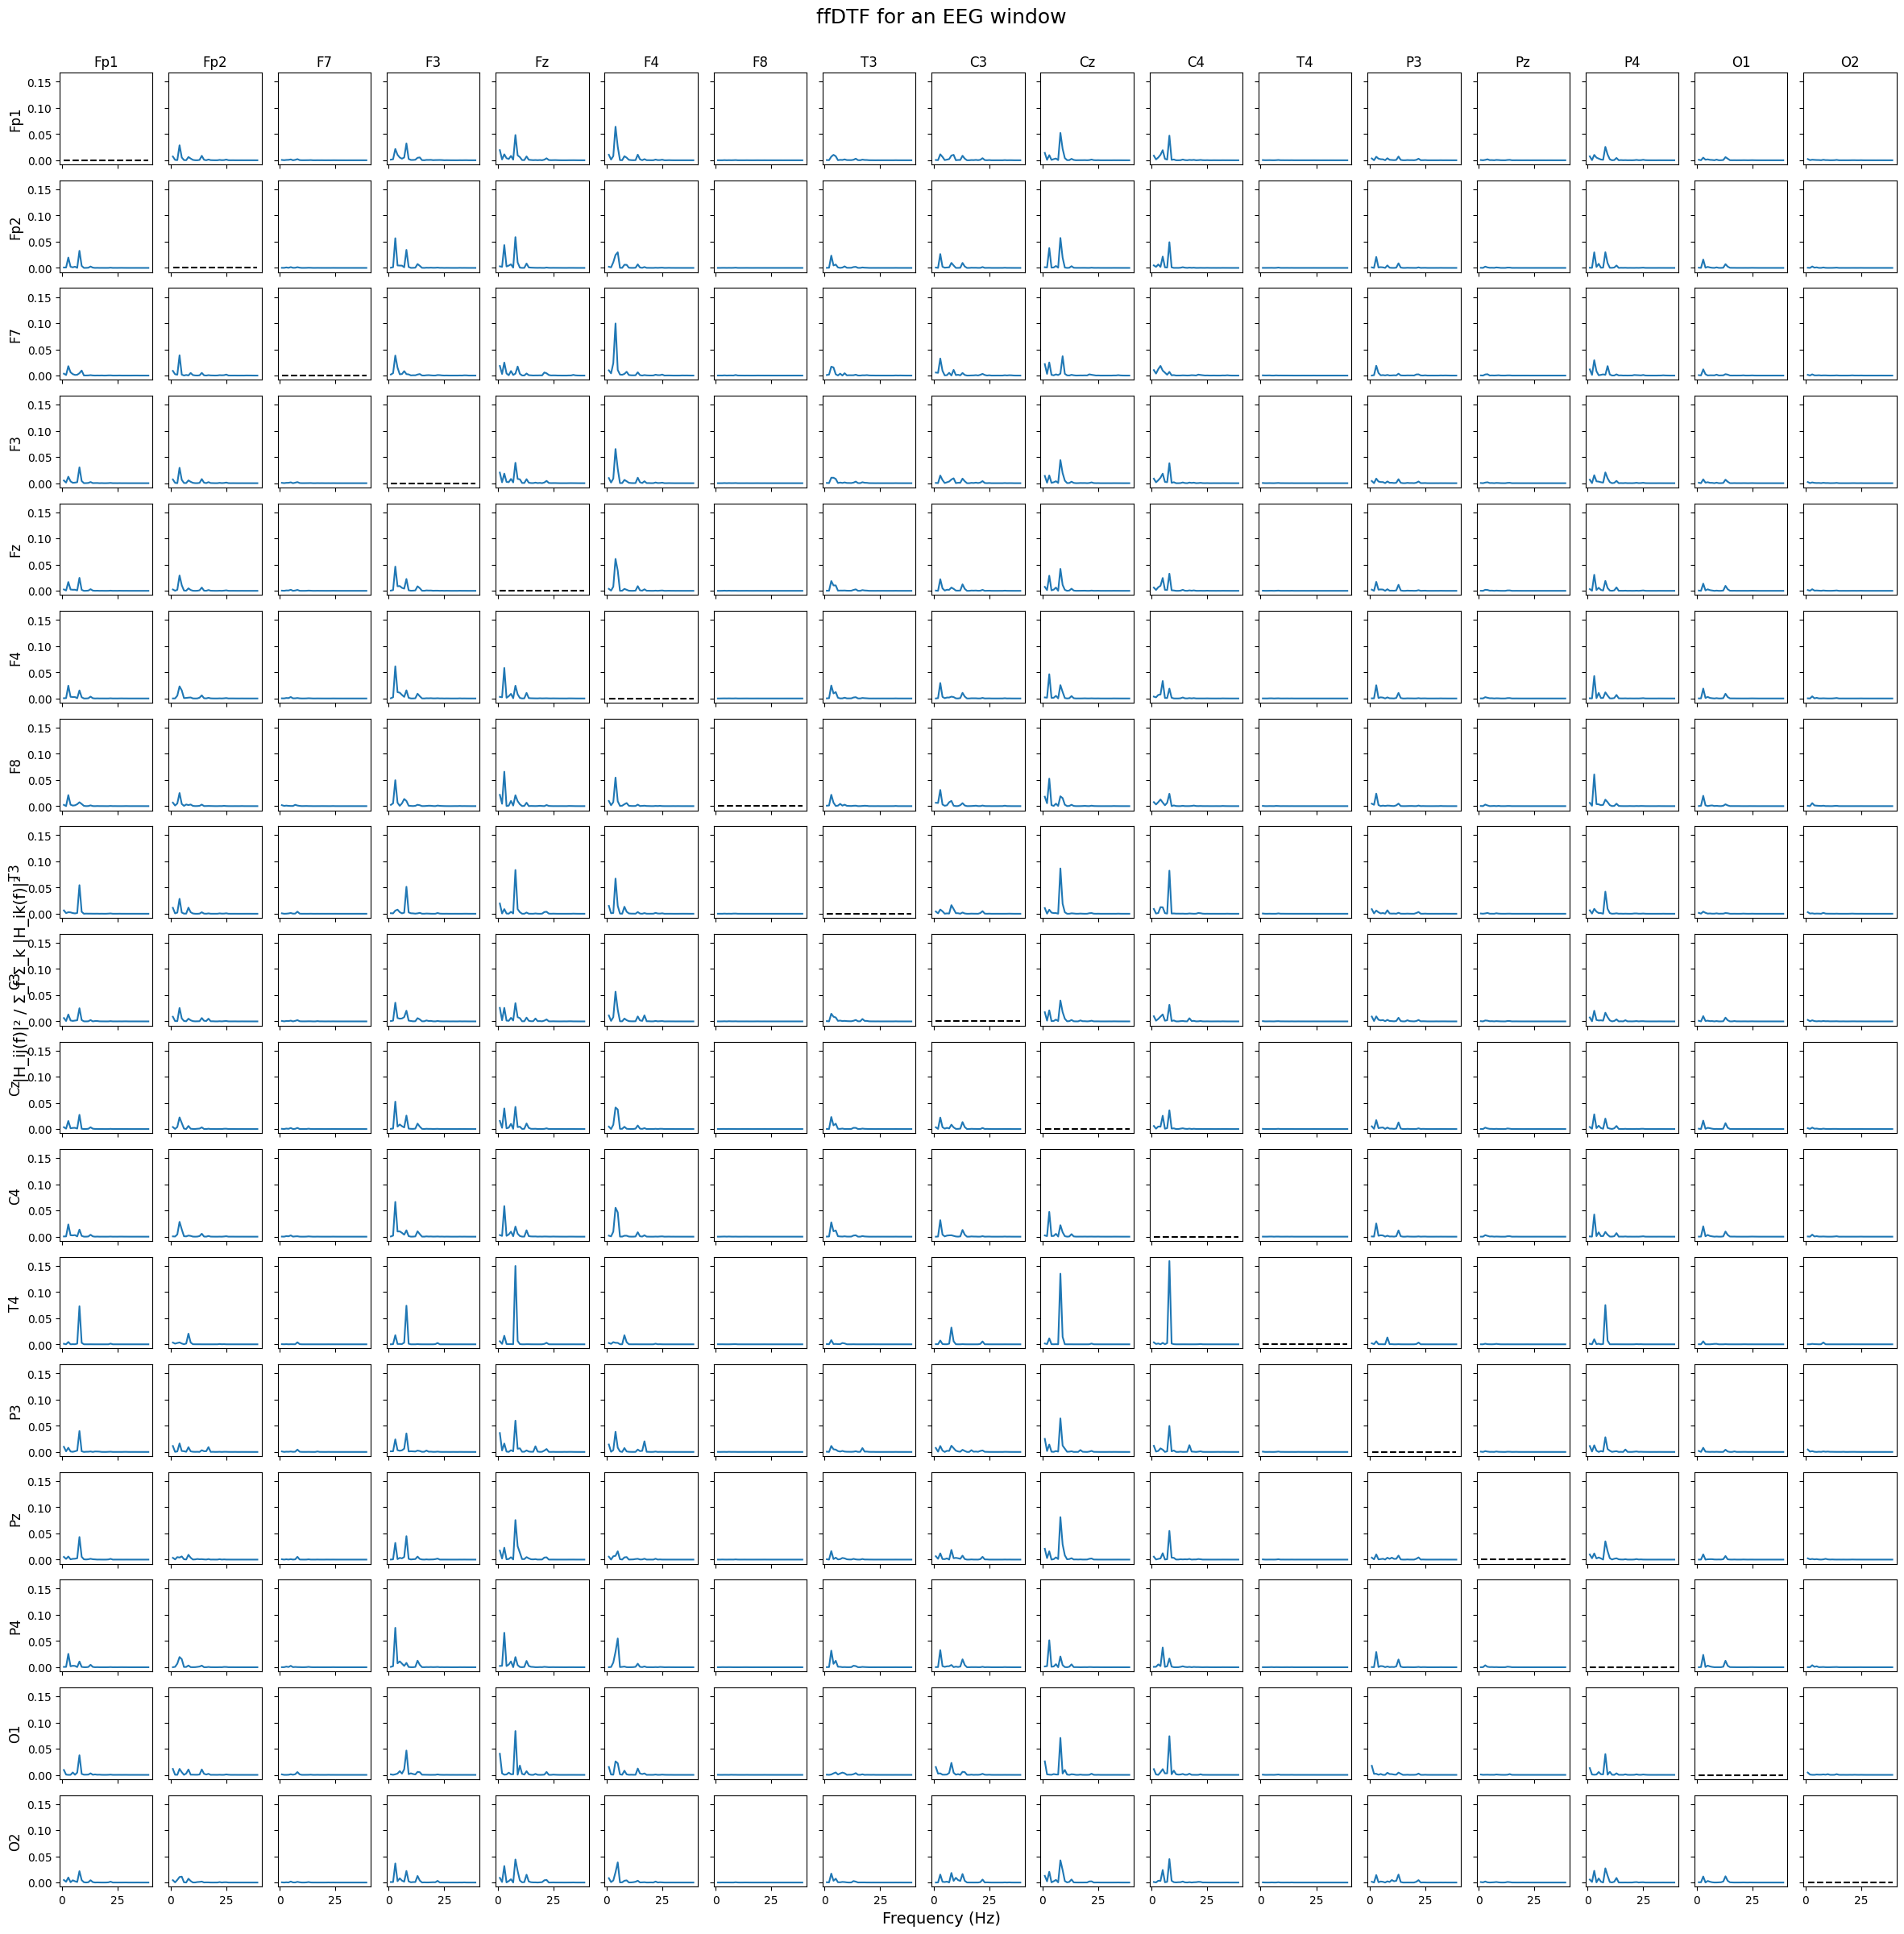

In [14]:
plot_all_flows(NDTF, ylabel = "|H|²", conn_name = 'NDTF')
plot_all_flows(ffDTF) #ylabel and name are set default to ffDTF

## create connectivity matrices aggregated over frequency bands

Use ordering invariant aggregation (sum by default, mean can also be used).

In [18]:
NDTF_bands = aggregate_bands(NDTF)
ffDTF_bands = aggregate_bands(ffDTF)

## visualize connectivity by bands

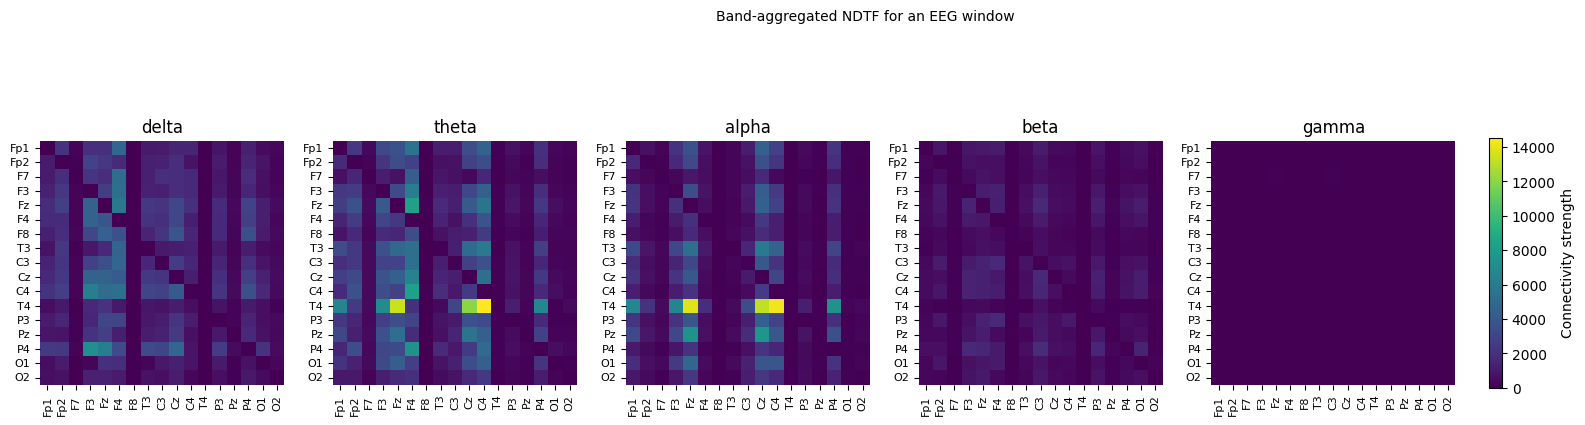

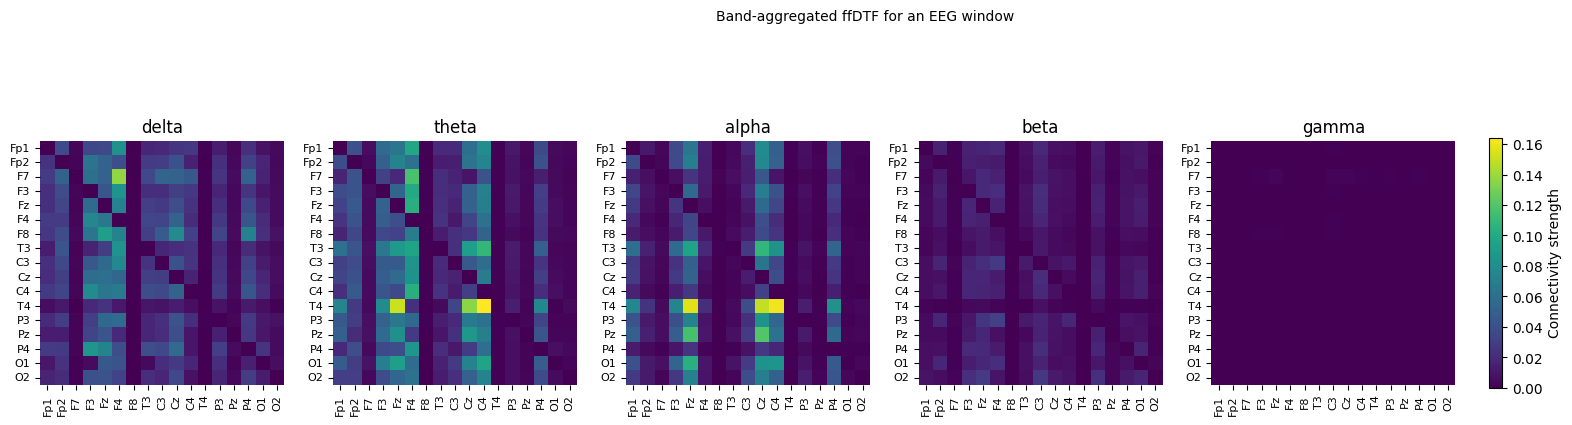

In [19]:
heatmap_bands_dict(NDTF_bands, conn_name = 'NDTF')
heatmap_bands_dict(ffDTF_bands)
plt.show()

#sprawdzić czy nie ma transpozycji

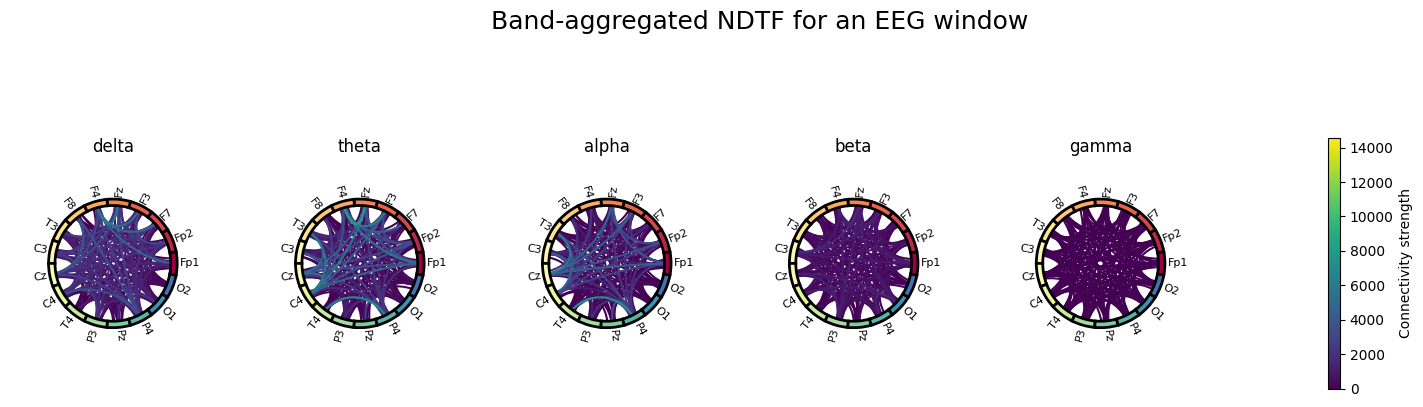

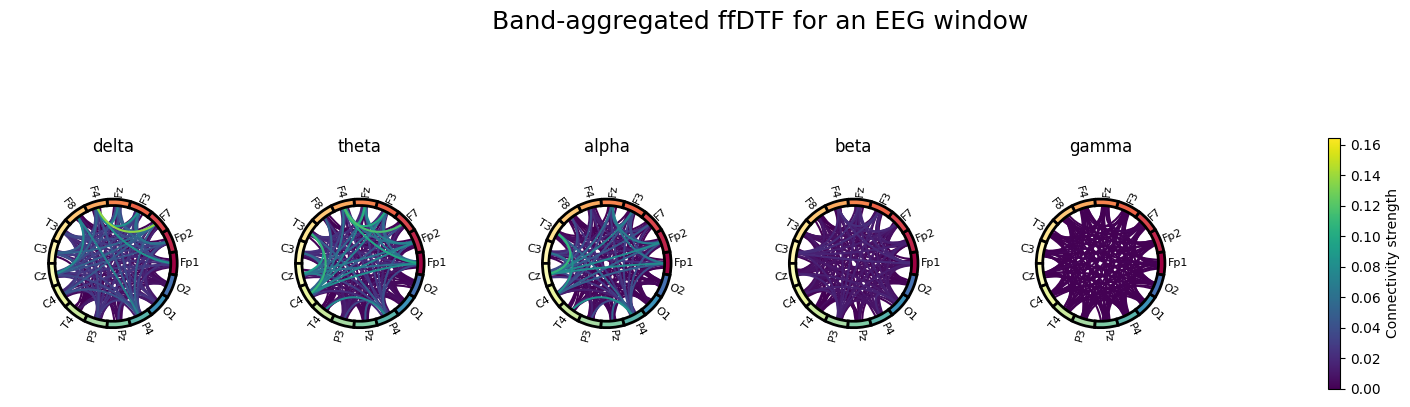

In [20]:
circle_bands_dict(NDTF_bands, conn_name = 'NDTF')
circle_bands_dict(ffDTF_bands)
plt.show()

## bands & graphs (visualize & create) with montage

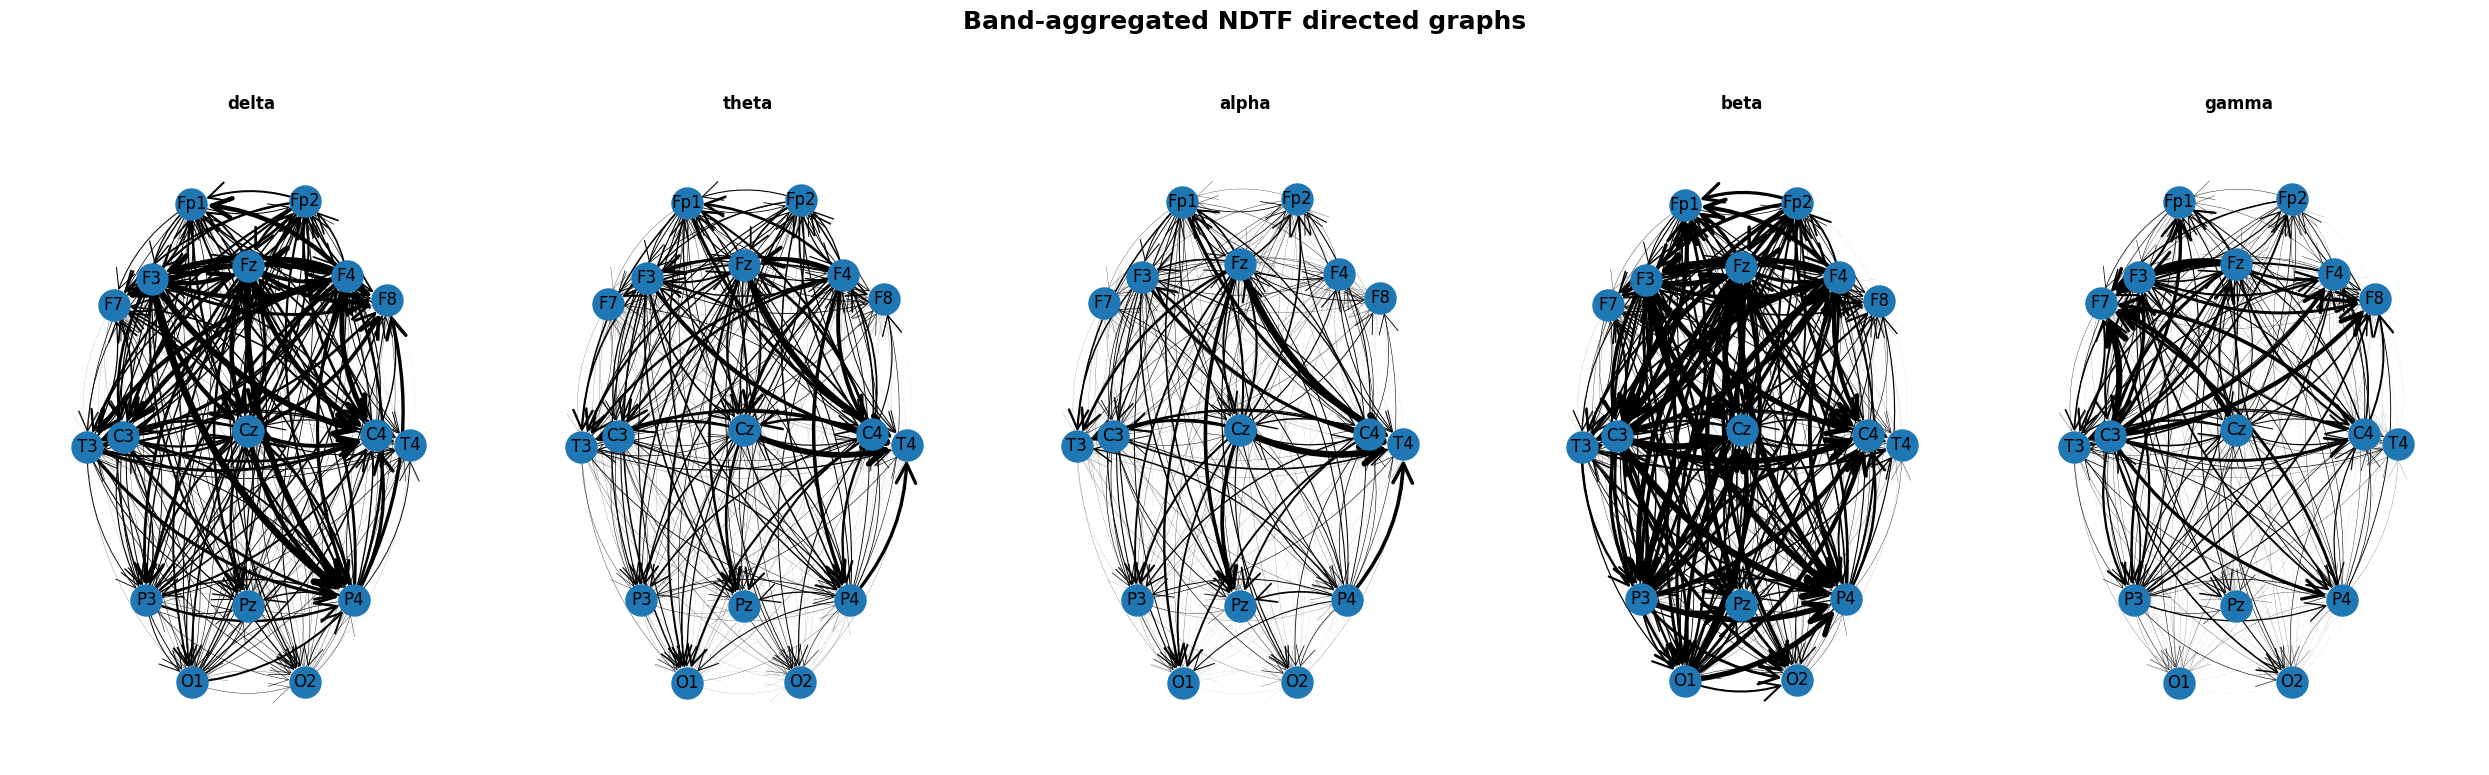

In [21]:
Gs_NDTF = graph_bands(NDTF_bands, conn_name = 'NDTF')
plt.show()

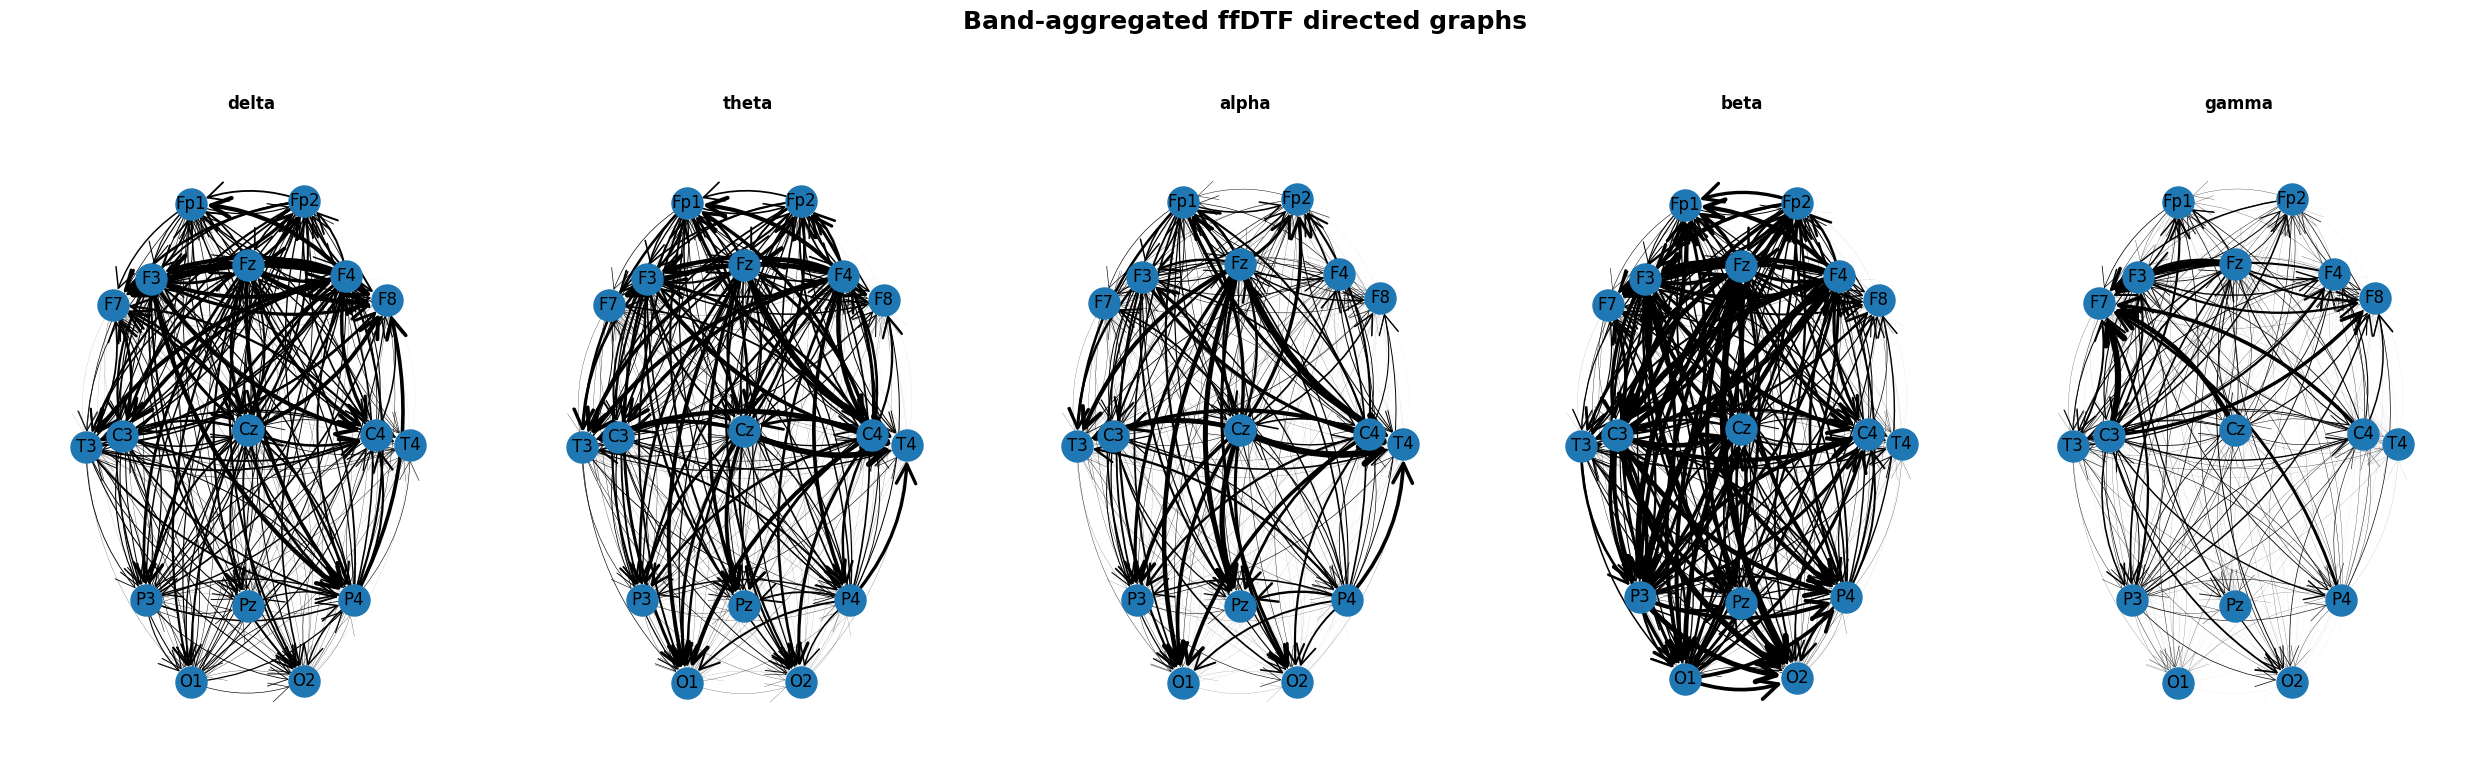

In [22]:
Gs_ffDTF = graph_bands(ffDTF_bands)
plt.show()

In [23]:
Gs_ffDTF_GA_metrics = compute_metrics_all(Gs_ffDTF)
# Gs_ffDTF is a dict of nx.DiGraphs with band-names as keys
#GT = Gs_ffDTF['theta'], then the single graph metrics can be computed as compute_graph_metrics(GT)

/dmj/fizmed/mmarzec/licencjat_neuro/venv_magisterka/lib/python3.11/site-packages/networkx/algorithms/assortativity/correlation.py:302: RuntimeWarning: invalid value encountered in scalar divide
  return float((xy * (M - ab)).sum() / np.sqrt(vara * varb))
2026-11-24 11:54:08,445 [WARNING] Eigenvector centrality did not converge. Returning NaN for all nodes.


In [24]:
GT = Gs_ffDTF['theta']
m = compute_graph_metrics(GT)
m

{'density': 1.0,
 'transitivity': 1.0,
 'average_clustering': 0.12814246666332502,
 'global_efficiency': 1.0,
 'local_efficiency': 1.0,
 'average_path_length': 1.0,
 'degree_assortativity': nan,
 'small_world_sigma': np.float64(0.1391284172630082),
 'degree_centrality': {0: 1.0,
  1: 1.0,
  2: 1.0,
  3: 1.0,
  4: 1.0,
  5: 1.0,
  6: 1.0,
  7: 1.0,
  8: 1.0,
  9: 1.0,
  10: 1.0,
  11: 1.0,
  12: 1.0,
  13: 1.0,
  14: 1.0,
  15: 1.0,
  16: 1.0},
 'betweenness_centrality': {0: 0.0,
  1: 0.0,
  2: 0.03333333333333333,
  3: 0.0,
  4: 0.0,
  5: 0.0,
  6: 0.13333333333333333,
  7: 0.0,
  8: 0.0,
  9: 0.0,
  10: 0.0,
  11: 0.5333333333333333,
  12: 0.0,
  13: 0.0,
  14: 0.0,
  15: 0.1,
  16: 0.125},
 'eigenvector_centrality': {0: 0.3241431014832504,
  1: 0.2913103024140854,
  2: 0.19557585438829198,
  3: 0.3183150279329081,
  4: 0.33325312866072954,
  5: 0.3854042035658574,
  6: 0.08711107864798477,
  7: 0.25787274631077917,
  8: 0.1636773199265831,
  9: 0.314384811583085,
  10: 0.400018715616

## graphs with only the strongest connections

Although the [EEGraph](https://github.com/ufvceiec/EEGRAPH/tree/feature/graph-metrics) package was not used, the thresholding/ top % convention and adding montagie position to graphs was inspired from it. Also, it enables to borrow compute_graph_metrics to compute metrics from classical Graph Analysis from each single graph (treting as undirected).

The default is set to take 10% strongest connections.

The global mode choosed top % of connections from all (in all bands), that's why the number of edges chosen varies across bands. Contrary, the per band mode choosed the top from band-local edges, thus all bands have equal number of chosen ones.

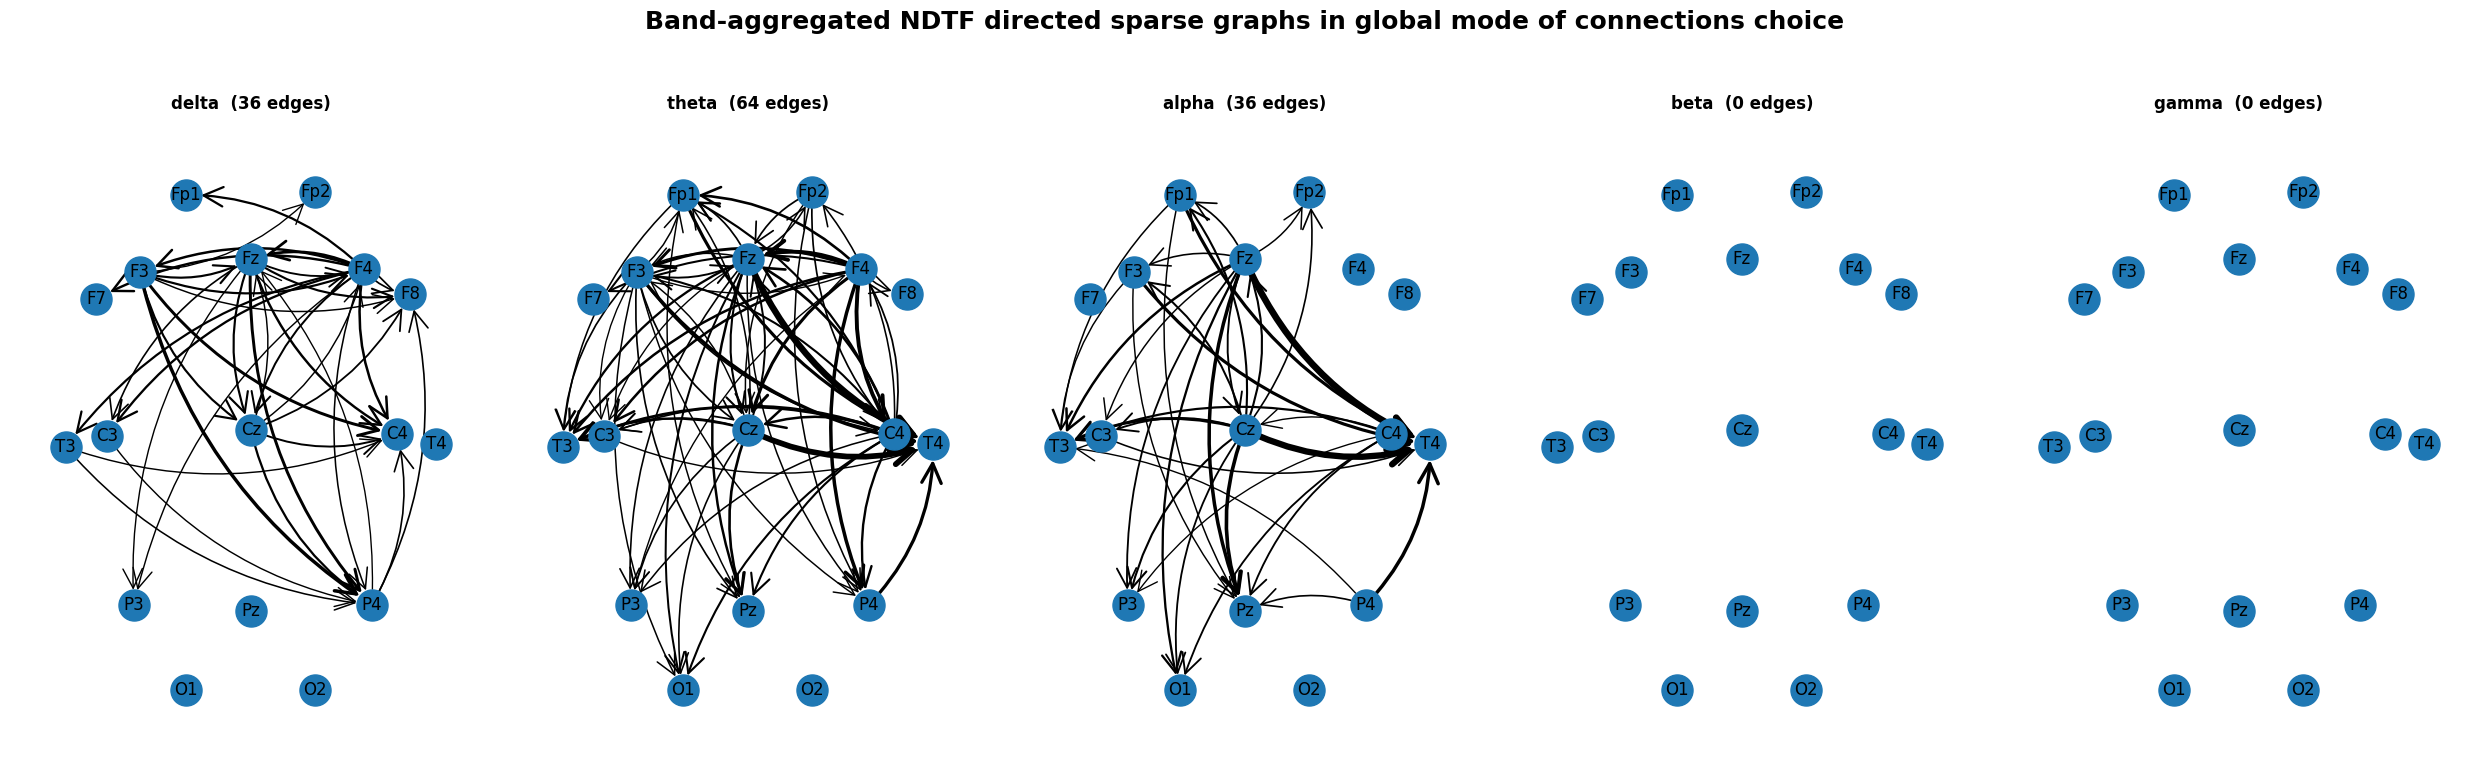

In [25]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'global', conn_name = 'NDTF')
plt.show()

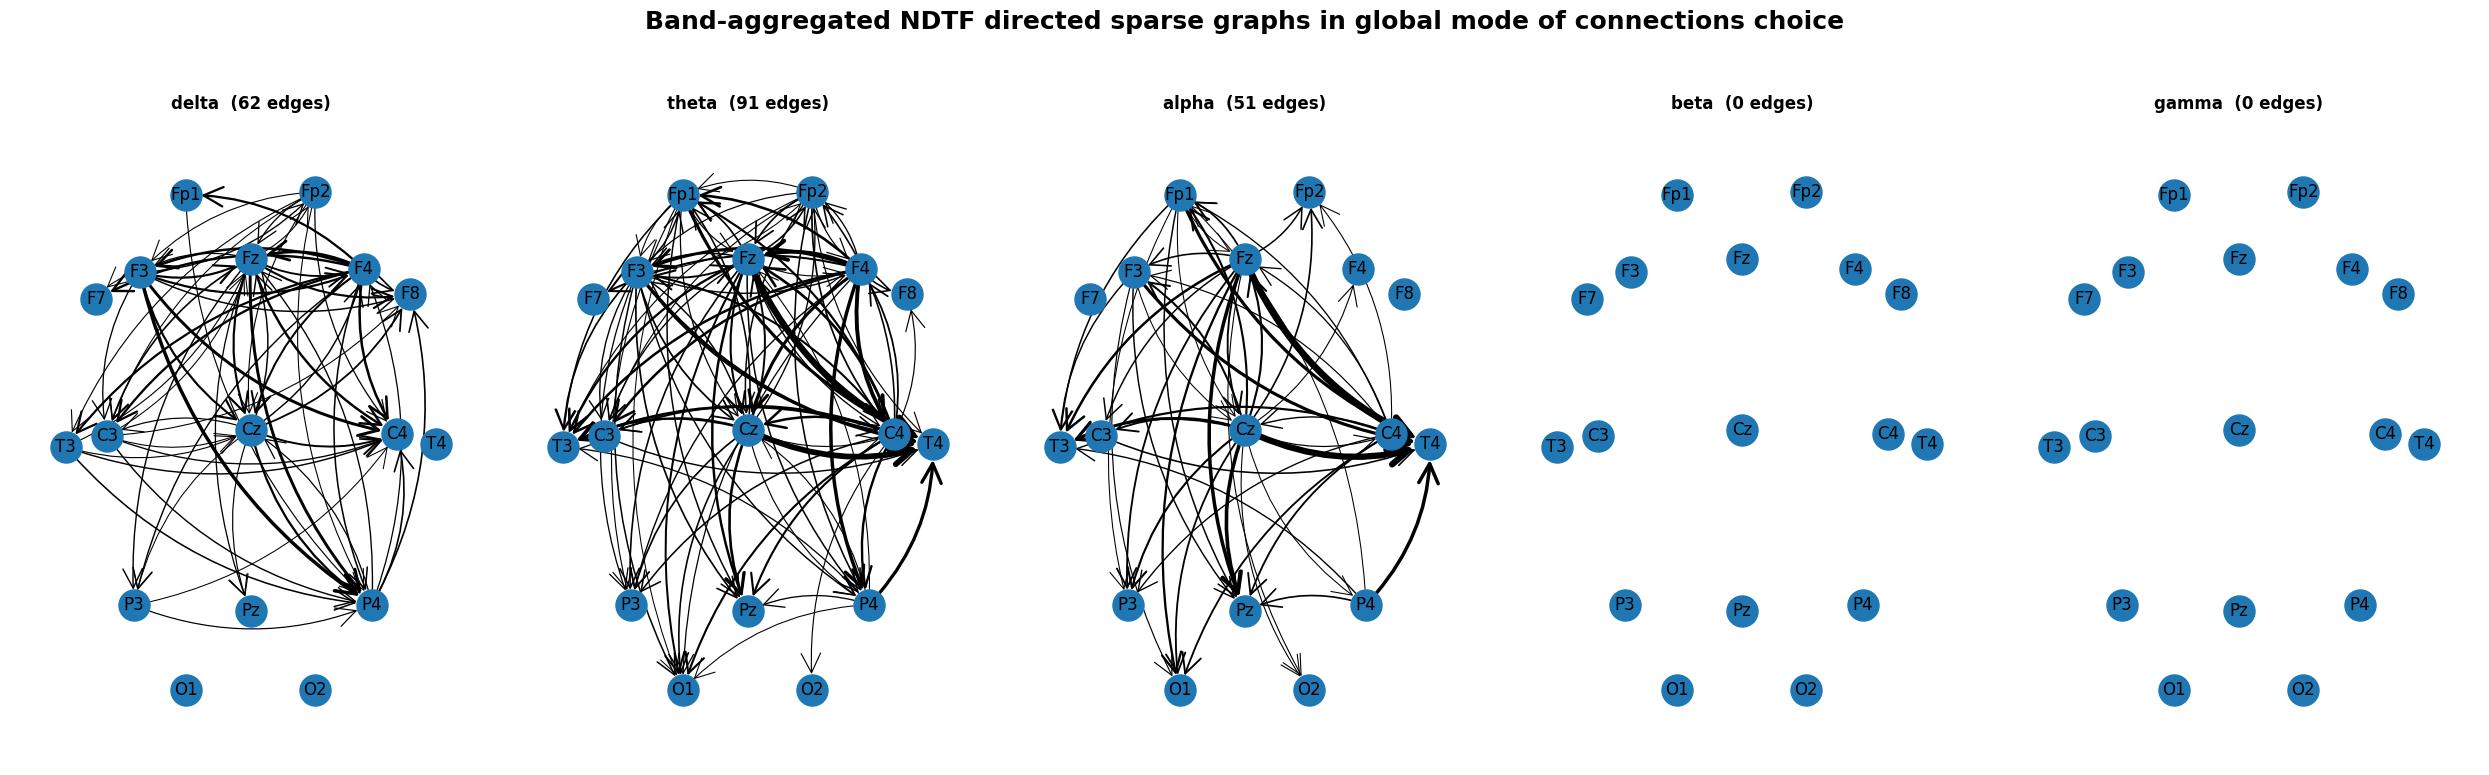

In [26]:
GsS_NDTF = graph_bands_sparse(NDTF_bands,top_percent = 15,  mode = 'global', conn_name = 'NDTF')
plt.show()

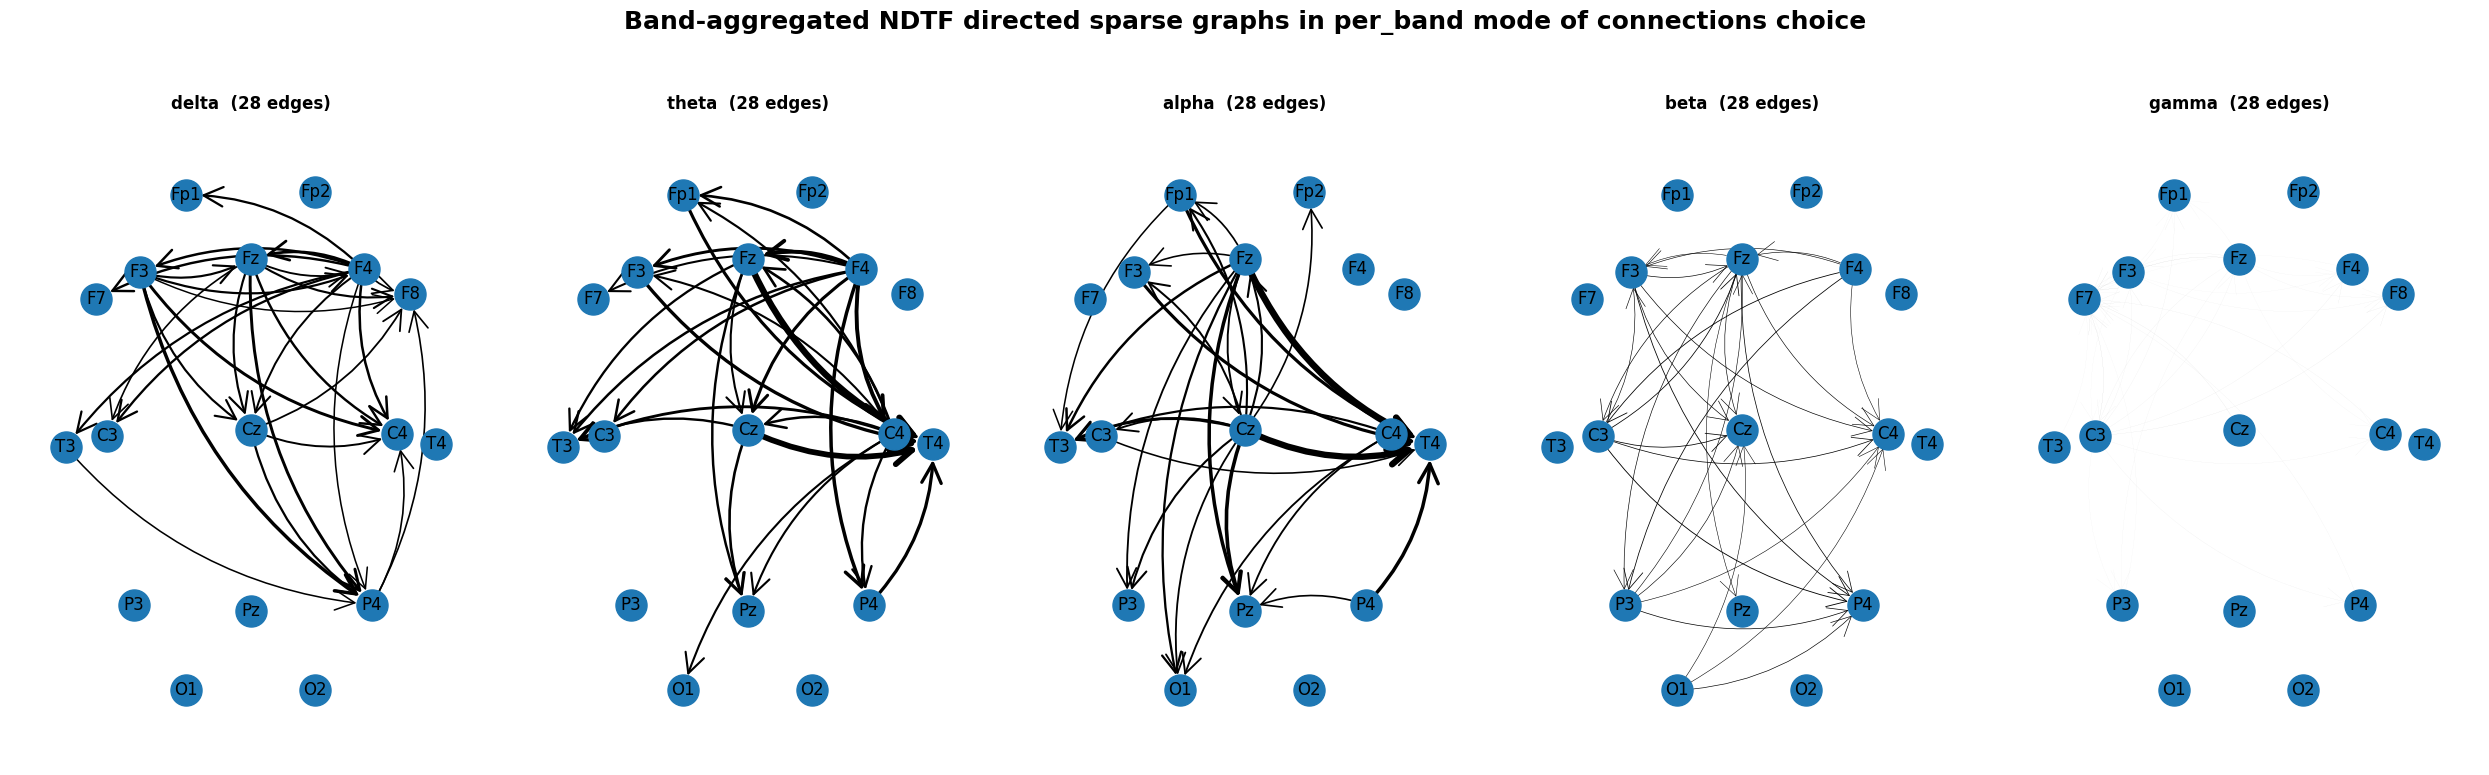

In [27]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'per_band', conn_name = 'NDTF')
plt.show()

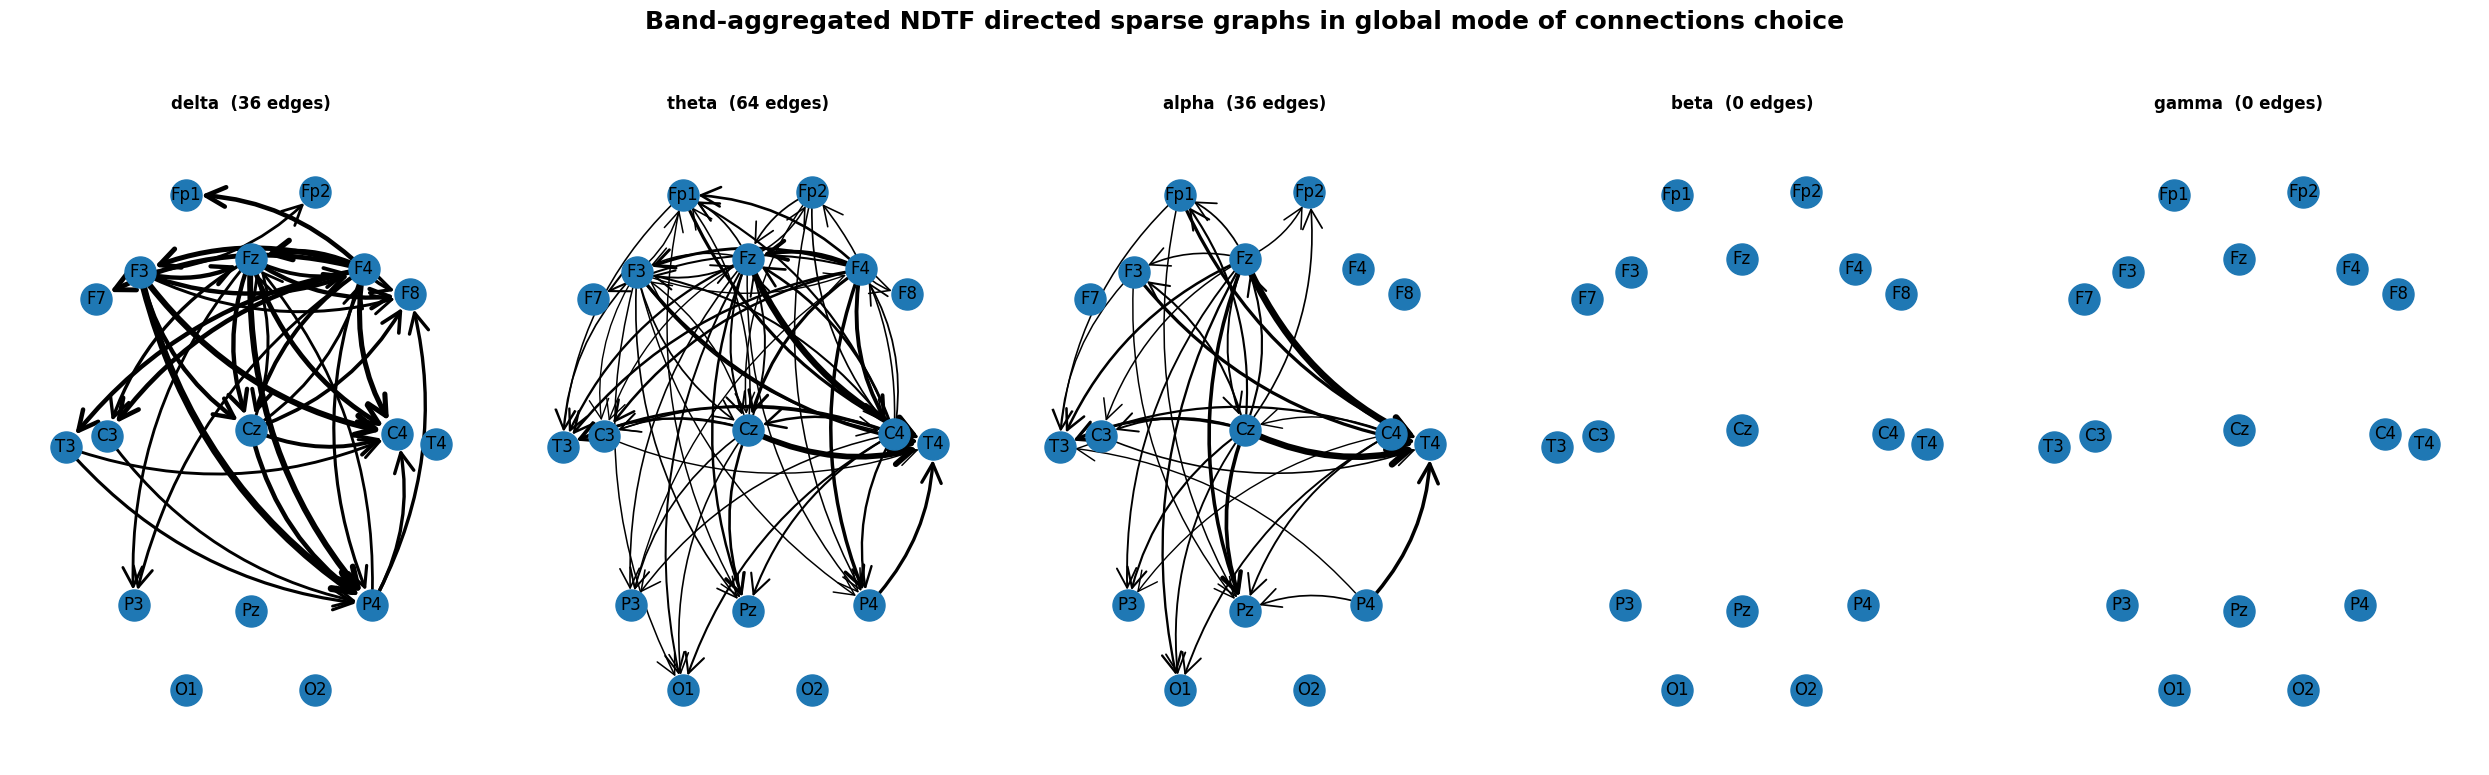

In [28]:
GsSB_NDTF = graph_bands_sparse(NDTF_bands, shared_scale = False, conn_name = 'NDTF')
plt.show()

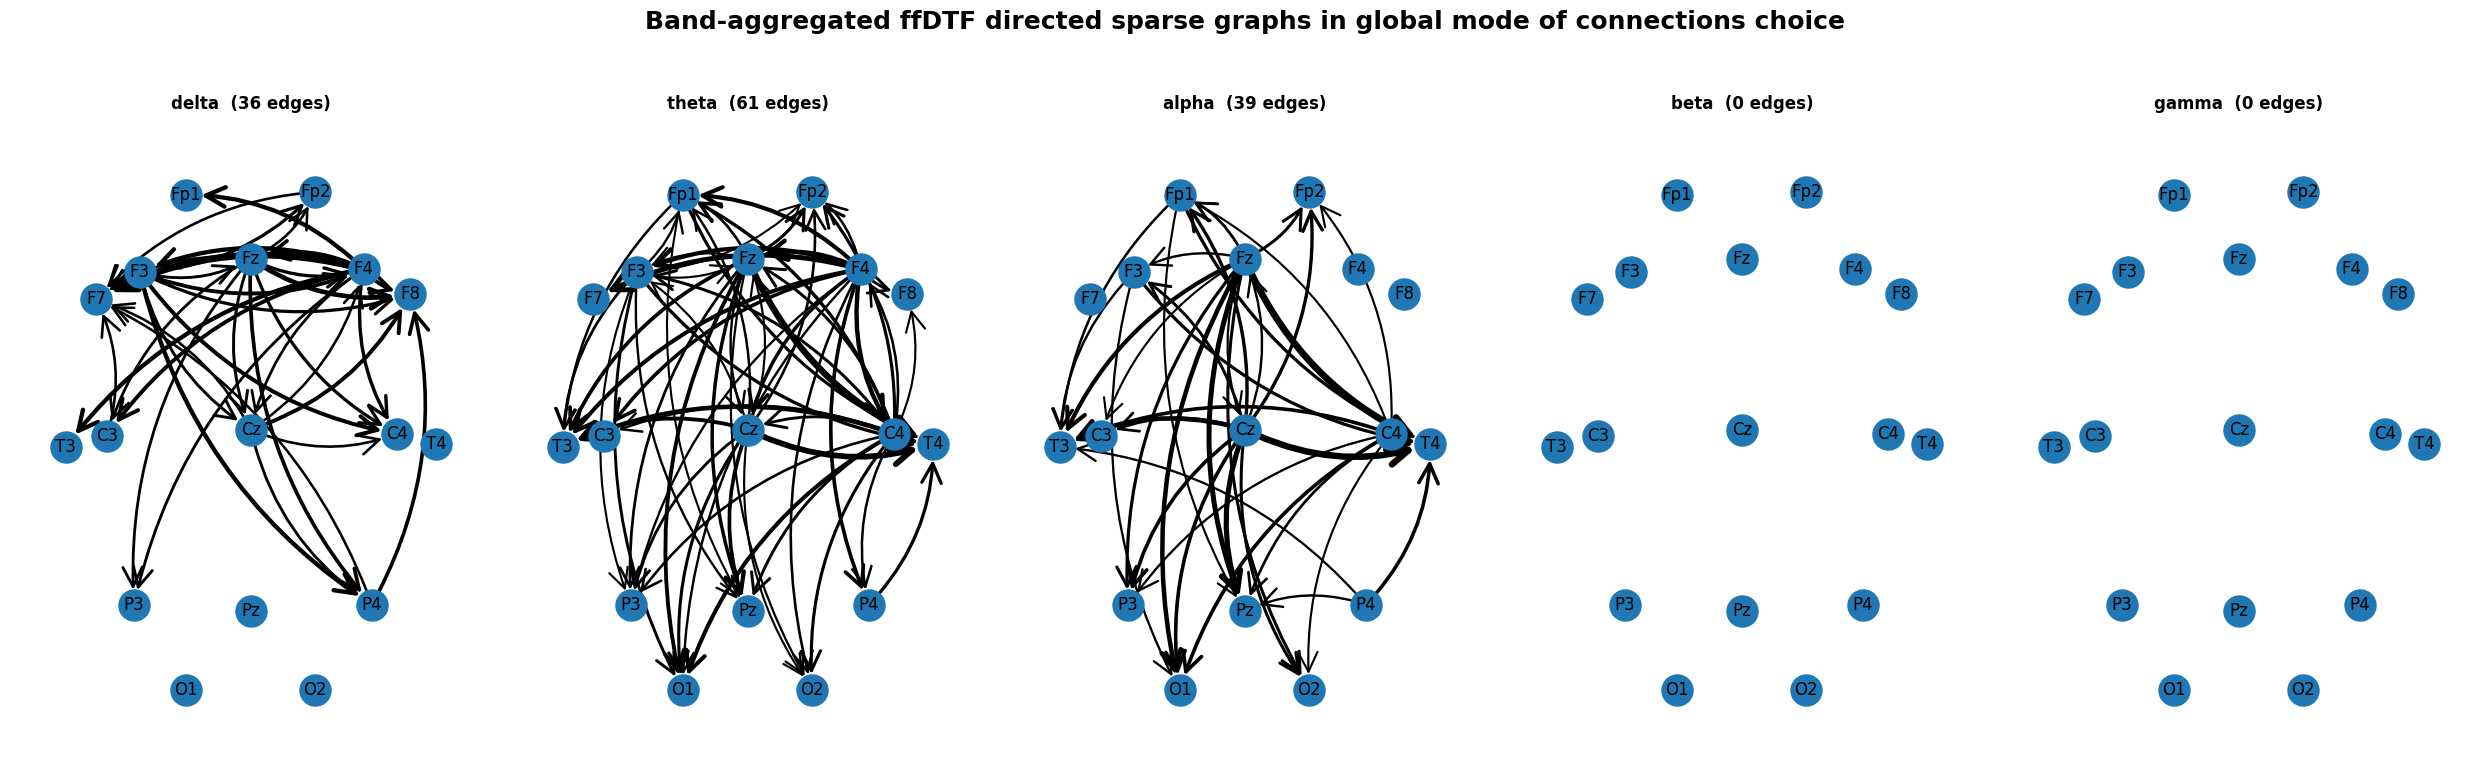

In [29]:
GsS_ffDTF = graph_bands_sparse(ffDTF_bands, shared_scale = False)
plt.show()

These two are the stringest candidates for graph features

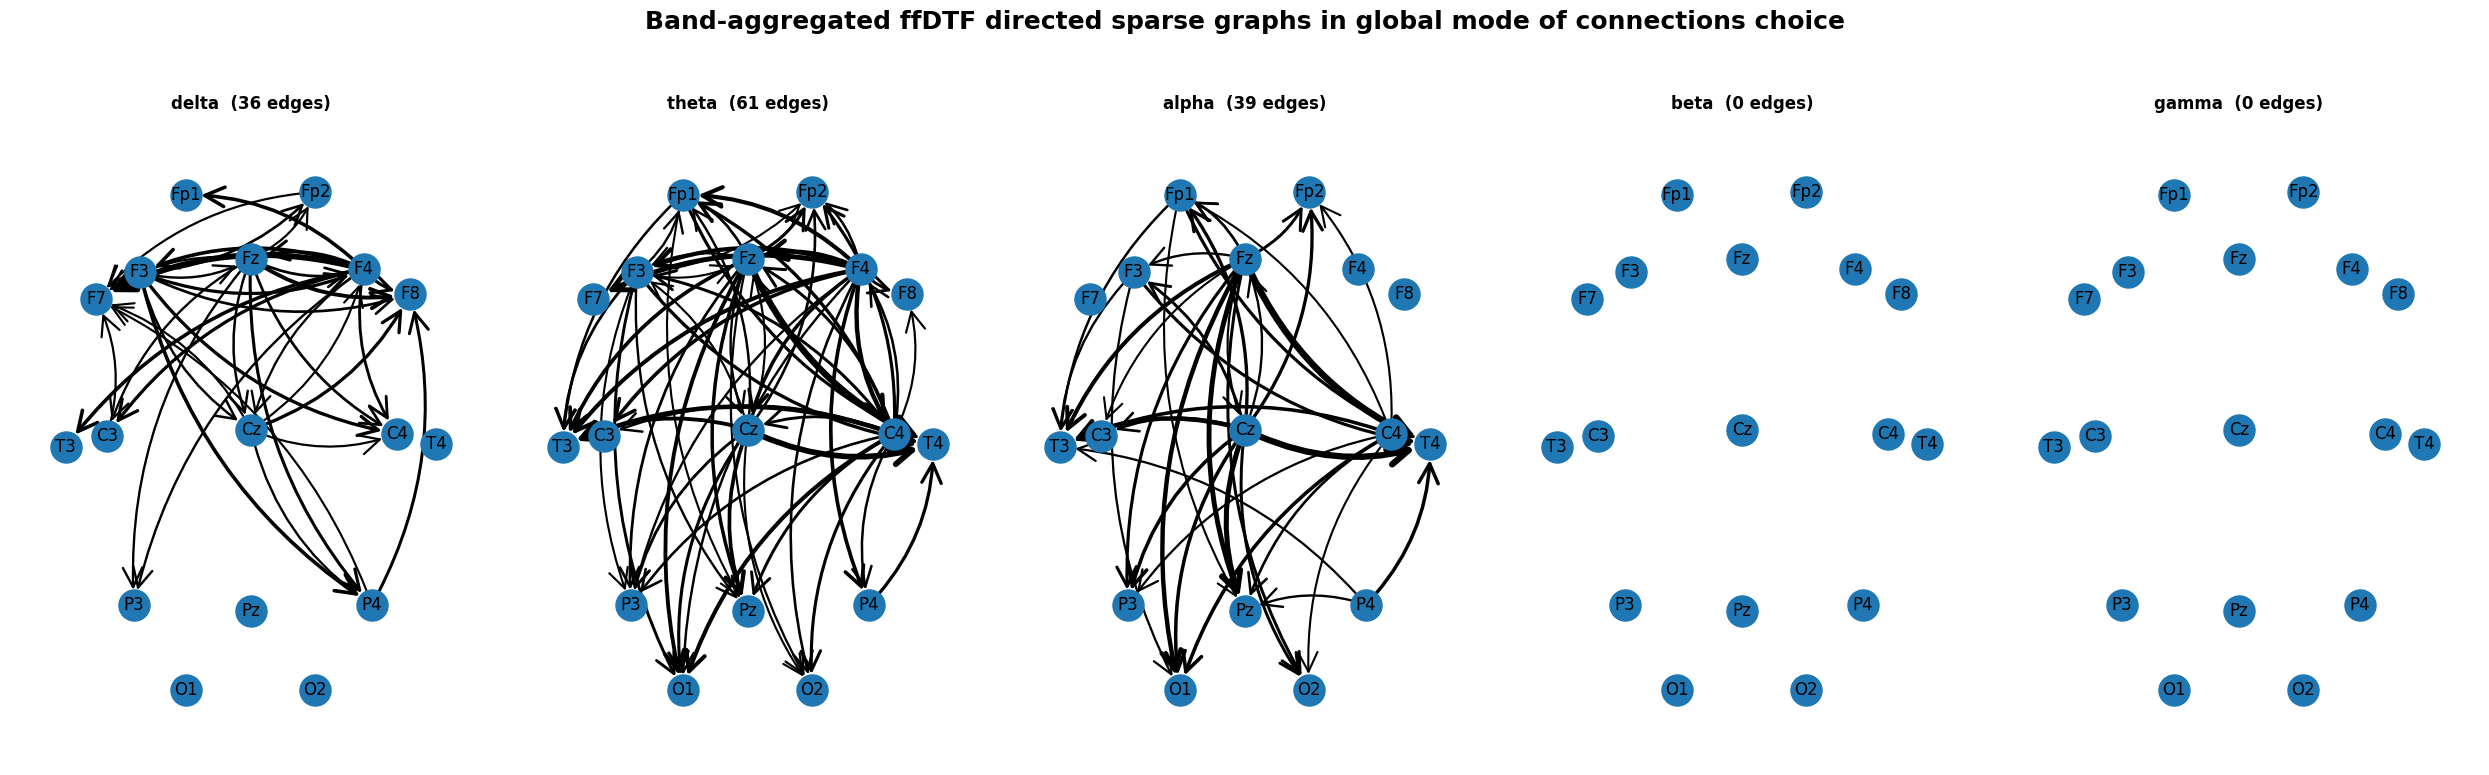

In [30]:
GsSB_ffDTF = graph_bands_sparse(ffDTF_bands, shared_scale = True)
plt.show()

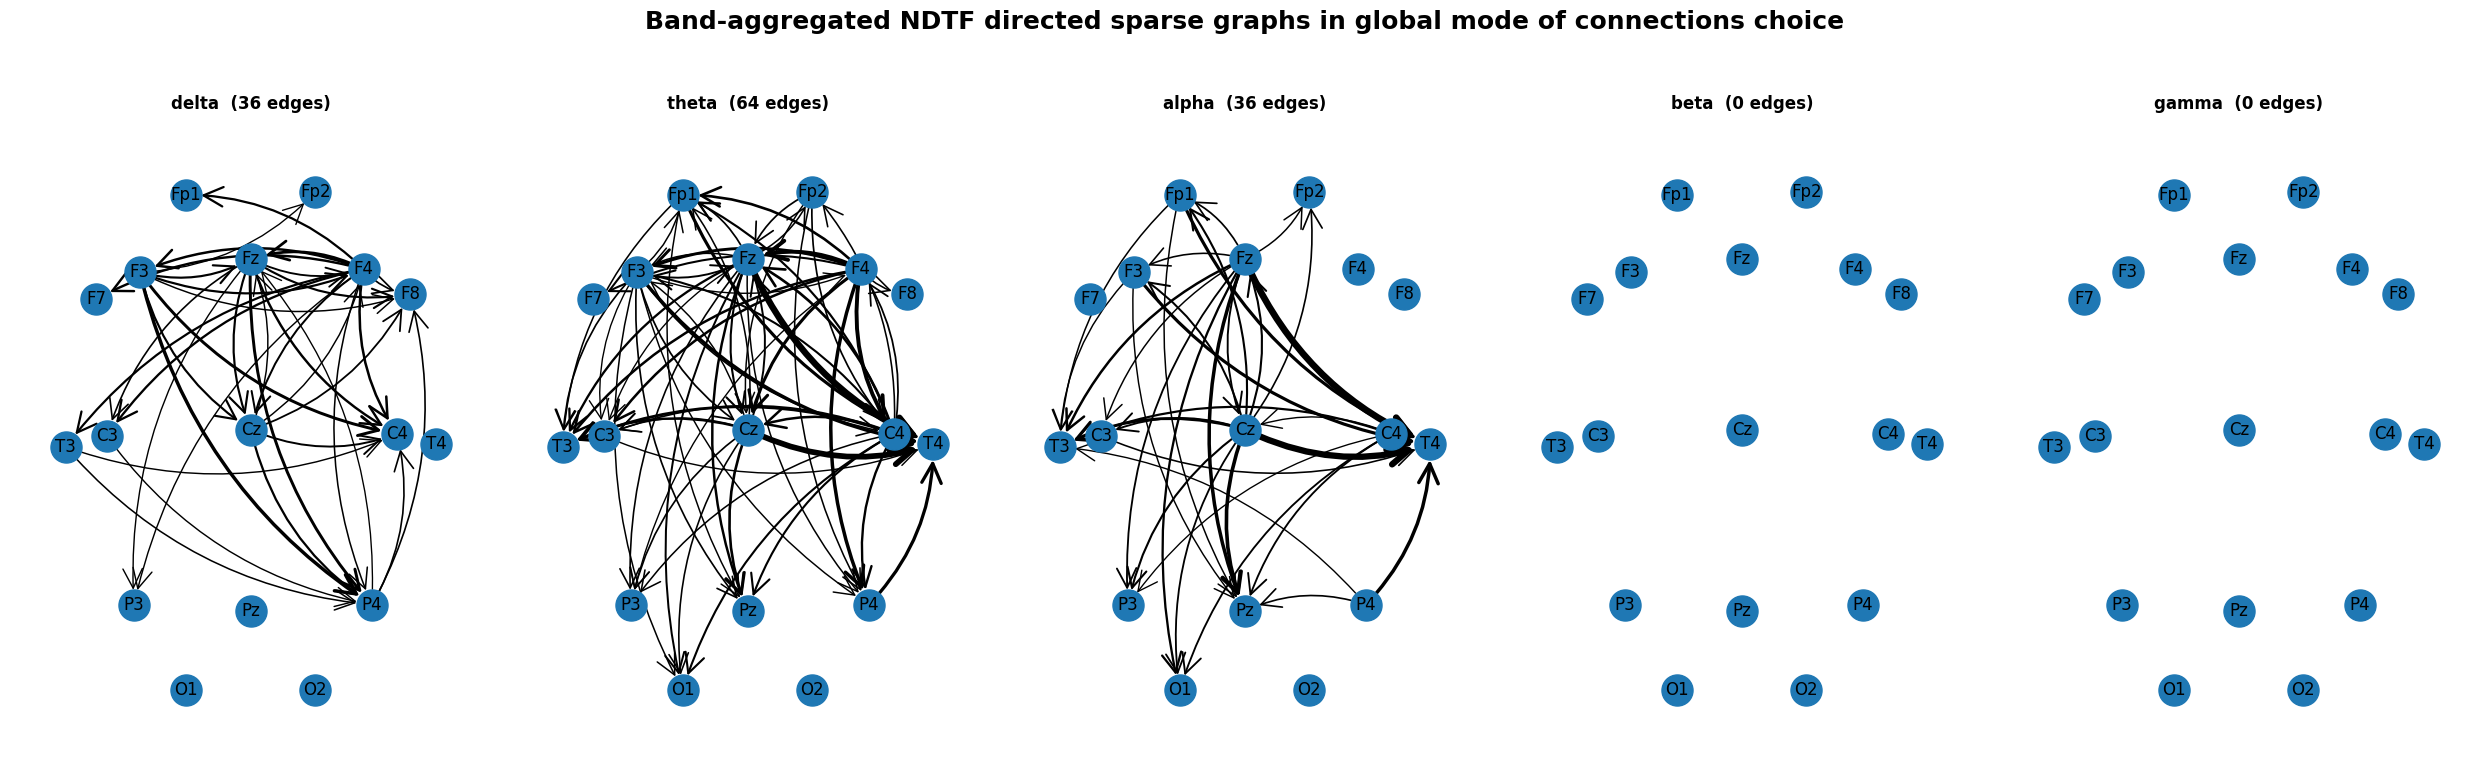

In [31]:
GsS_NDTF = graph_bands_sparse(NDTF_bands, mode = 'global', conn_name = 'NDTF')
plt.show()

## networkx -> pytorch_geometric object

In [33]:
GsSB_ffDTF['alpha'].edges(data = True)

OutEdgeDataView([(0, 7, {'weight': 0.058908994403343816}), (0, 11, {'weight': 0.0756263425251421}), (0, 13, {'weight': 0.0498725604763009}), (3, 7, {'weight': 0.05594024631811393}), (3, 11, {'weight': 0.07485649736769566}), (3, 15, {'weight': 0.05316704052439642}), (4, 0, {'weight': 0.06431031894343603}), (4, 1, {'weight': 0.06980752832841733}), (4, 3, {'weight': 0.05525886149119106}), (4, 7, {'weight': 0.09549557951394202}), (4, 8, {'weight': 0.04958799988829287}), (4, 9, {'weight': 0.05109077538073779}), (4, 11, {'weight': 0.1563820087455176}), (4, 12, {'weight': 0.07352247675938955}), (4, 13, {'weight': 0.11594922255617772}), (4, 15, {'weight': 0.10420131640966934}), (4, 16, {'weight': 0.07095663050823134}), (9, 0, {'weight': 0.07866988817024209}), (9, 1, {'weight': 0.07759267547613245}), (9, 3, {'weight': 0.06870145708371386}), (9, 4, {'weight': 0.05553515285282744}), (9, 7, {'weight': 0.10835178132471476}), (9, 8, {'weight': 0.06331587361462485}), (9, 11, {'weight': 0.149128812598

In [ ]:
#graph = from_networkx(GsSB_ffDTF['Alpha'], group_edge_attrs = ['weight'])
#graph

In [ ]:
#for prop in graph: #type:ignore
    #print(prop)